# Modelos de clasificación de clubes de convergencia (datos 2023)

In [1]:
import warnings
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from scipy.stats import skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    LeaveOneOut,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:  # por si se ejecuta fuera de Jupyter
    display = print

SEMILLA = 42
N_JOBS = -1  # usa todos los núcleos; pon 1 si Windows da "TerminatedWorkerError"
SK_NUEVO = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)

C:\Users\Lucia\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Lucia\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [18]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

## 1. Carga y preparación de datos

In [2]:
RUTAS = ["todos los determinantes.xlsx", "todos_los_determinantes.xlsx"]
ruta = next((Path(r) for r in RUTAS if Path(r).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No encuentro el Excel en {Path.cwd()}. Probé: {RUTAS}")

datos = pd.read_excel(ruta).drop(columns=["Unnamed: 2"], errors="ignore")

# Columnas numéricas que vienen como texto (valores '..' o con coma decimal) -> número
COLS_ID = ["PAIS", "PAIS.1", "CLUB", "AÑO"]
for col in datos.columns.difference(COLS_ID):
    datos[col] = pd.to_numeric(
        datos[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce",   # '..' y similares pasan a NaN
    )

# El club de cada país se toma del año 2000; las variables, del año 2023
club_por_pais = (
    datos.loc[datos["AÑO"] == 2000, ["PAIS.1", "CLUB"]]
    .drop_duplicates("PAIS.1")
    .set_index("PAIS.1")["CLUB"]
)

datos_2023 = (
    datos.loc[datos["AÑO"] == 2023]
    .drop(columns=["PAIS", "CLUB", "AÑO"])
    .set_index("PAIS.1")
)
datos_2023["CLUB"] = datos_2023.index.map(club_por_pais)
datos_2023 = datos_2023.dropna(subset=["CLUB"])
datos_2023["CLUB"] = datos_2023["CLUB"].astype(int)

X = datos_2023.drop(columns="CLUB")
y = datos_2023["CLUB"]          # entero (1, 2, 3), no categoría
CLASES = np.sort(y.unique())

print(f"{X.shape[0]} países, {X.shape[1]} variables | NaN en X: {int(X.isna().sum().sum())}")
print("Distribución de clubes:", y.value_counts().sort_index().to_dict())
print("Tipos:", X.dtypes.astype(str).unique().tolist())
X.head()

125 países, 10 variables | NaN en X: 0
Distribución de clubes: {1: 55, 2: 51, 3: 19}
Tipos: ['float64', 'int64']


,GOBERNANZA (C.PPAL),INTERNET,tasa femenina/tasa total,mujeres parlam(%),renovables,salud,%gto educa sobre pib,%gto educa sobre gto toal gob,KOFGI,tasa depobreza
PAIS.1,,,,,,,,,,
ALB,137.511394,22.504859,0.898551,35.714286,0.465410,71,3.10,10.9,65.941452,19.7
ARE,163.575461,37.096823,0.702381,50.000000,4.201346,84,3.89,14.8,77.334503,19.5
ARG,134.806713,25.358073,0.838235,43.190661,9.061921,80,5.89,13.2,66.875610,41.7
ARM,134.417185,18.545808,0.859375,35.514019,2.103059,69,2.40,9.0,68.236397,23.7
AUS,206.887207,36.627426,0.924242,38.410596,20.937361,89,5.10,12.6,79.494049,14.2


## 2. Resumen descriptivo

In [3]:
resumen = X.describe().T
resumen["rango"] = resumen["max"] - resumen["min"]
resumen["asimetria"] = X.apply(lambda s: skew(s.dropna()))
resumen[["min", "max", "rango", "mean", "std", "asimetria"]].round(3)

,min,max,rango,mean,std,asimetria
GOBERNANZA (C.PPAL),51.581,218.741,167.160,141.340,40.054,0.168
INTERNET,0.020,48.669,48.648,19.486,15.421,0.286
tasa femenina/tasa total,0.132,0.989,0.858,0.812,0.170,-1.815
mujeres parlam(%),0.000,61.250,61.250,27.060,12.830,0.115
renovables,-15.081,78.910,93.991,13.112,15.921,1.519
salud,32.000,92.000,60.000,72.336,14.169,-1.066
%gto educa sobre pib,0.300,9.200,8.900,4.229,1.642,0.246
%gto educa sobre gto toal gob,3.500,25.000,21.500,13.729,4.383,0.522
KOFGI,39.552,88.899,49.347,66.139,13.198,-0.061
tasa depobreza,0.000,75.200,75.200,22.894,14.640,1.314


## 3. Utilidades comunes

- `evaluar` imprime y guarda las métricas de cada modelo.
- `loocv_anidado` elige hiperparámetros con un CV de 5 folds **dentro** de cada fold del LOOCV, de modo que la métrica final no está inflada por haber optimizado sobre los mismos datos.

In [4]:
LOOCV = LeaveOneOut()
CV_INTERNO = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
resultados = {}


def evaluar(nombre, y_pred, detalle=True):
    resultados[nombre] = {
        "accuracy": accuracy_score(y, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "f1_macro": f1_score(y, y_pred, average="macro"),
    }
    print(f"Accuracy {nombre}: {resultados[nombre]['accuracy']:.2%}")
    print(f"Balanced accuracy {nombre}: {resultados[nombre]['balanced_accuracy']:.2%}")
    if detalle:
        matriz = pd.DataFrame(
            confusion_matrix(y, y_pred, labels=CLASES),
            index=[f"real_{c}" for c in CLASES],
            columns=[f"pred_{c}" for c in CLASES],
        )
        print("Matriz de confusión:")
        print(matriz)
        print(classification_report(y, y_pred, zero_division=0))


def preprocesamiento(escalar=True):
    pasos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalar", StandardScaler()))
    return Pipeline(pasos)


def logistica(tipo):
    """Regresión logística multinomial: 'lasso' (L1) o 'elasticnet'.
    Compatible con scikit-learn < 1.8 (penalty) y >= 1.8 (l1_ratio)."""
    base = dict(solver="saga", max_iter=5000, tol=1e-3, random_state=SEMILLA)
    if SK_NUEVO:
        return LogisticRegression(l1_ratio={"lasso": 1.0, "elasticnet": 0.5}[tipo], **base)
    if tipo == "lasso":
        return LogisticRegression(penalty="l1", **base)
    return LogisticRegression(penalty="elasticnet", l1_ratio=0.5, **base)


def loocv_anidado(nombre, modelo, rejilla):
    busqueda = GridSearchCV(
        modelo, rejilla, cv=CV_INTERNO, scoring="balanced_accuracy", n_jobs=1
    )
    with warnings.catch_warnings():
        # Los C grandes no convergen con saga y simplemente puntúan mal en la búsqueda
        warnings.simplefilter("ignore", ConvergenceWarning)
        y_pred = cross_val_predict(busqueda, X, y, cv=LOOCV, n_jobs=N_JOBS)
        evaluar(nombre, y_pred)
        # Ajuste final con todos los datos (para interpretar hiperparámetros/coeficientes)
        busqueda.fit(X, y)
    print("Hiperparámetros del ajuste final:", busqueda.best_params_)
    return busqueda

## 4. Regresión logística (línea base)

In [5]:
modelo_log = Pipeline([
    ("prep", preprocesamiento()),
    ("clf", LogisticRegression(max_iter=1000)),
])
y_pred_log = cross_val_predict(modelo_log, X, y, cv=LOOCV, n_jobs=N_JOBS)
evaluar("Logística (L2)", y_pred_log)

Accuracy Logística (L2): 74.40%
Balanced accuracy Logística (L2): 68.50%
Matriz de confusión:
        pred_1  pred_2  pred_3
real_1      46       9       0
real_2       9      38       4
real_3       0      10       9
              precision    recall  f1-score   support

           1       0.84      0.84      0.84        55
           2       0.67      0.75      0.70        51
           3       0.69      0.47      0.56        19

    accuracy                           0.74       125
   macro avg       0.73      0.69      0.70       125
weighted avg       0.75      0.74      0.74       125



## 5. Lasso (L1)

In [6]:
modelo_lasso = Pipeline([("prep", preprocesamiento()), ("clf", logistica("lasso"))])
rejilla_lasso = {
    "clf__C": np.logspace(-2, 1, 7),
    "clf__class_weight": [None, "balanced"],
}
busqueda_lasso = loocv_anidado("Lasso", modelo_lasso, rejilla_lasso)

Accuracy Lasso: 73.60%
Balanced accuracy Lasso: 72.30%
Matriz de confusión:
        pred_1  pred_2  pred_3
real_1      45      10       0
real_2       7      34      10
real_3       0       6      13
              precision    recall  f1-score   support

           1       0.87      0.82      0.84        55
           2       0.68      0.67      0.67        51
           3       0.57      0.68      0.62        19

    accuracy                           0.74       125
   macro avg       0.70      0.72      0.71       125
weighted avg       0.74      0.74      0.74       125

Hiperparámetros del ajuste final: {'clf__C': 1.0, 'clf__class_weight': 'balanced'}


In [7]:
# Variables seleccionadas por el Lasso (coeficiente != 0 en alguna clase)
clf = busqueda_lasso.best_estimator_.named_steps["clf"]
coef = pd.DataFrame(
    clf.coef_.T, index=X.columns, columns=[f"coef_club_{c}" for c in clf.classes_]
)
seleccionadas = coef[(coef.abs() > 1e-8).any(axis=1)]
print(f"Variables seleccionadas: {len(seleccionadas)} de {X.shape[1]}")
display(seleccionadas.round(3))

Variables seleccionadas: 9 de 10


,coef_club_1,coef_club_2,coef_club_3
GOBERNANZA (C.PPAL),0.962,0.000,-0.442
INTERNET,1.307,0.000,-0.167
mujeres parlam(%),0.168,0.000,-0.193
renovables,0.000,0.000,0.223
salud,-0.109,0.922,0.000
%gto educa sobre pib,0.000,-0.002,0.515
%gto educa sobre gto toal gob,0.147,0.000,-0.437
KOFGI,0.833,0.000,-0.838
tasa depobreza,-0.597,0.000,0.000


## 6. Elastic Net

In [8]:
modelo_en = Pipeline([
    ("prep", preprocesamiento()),
    ("clf", logistica("elasticnet").set_params(class_weight="balanced")),
])
rejilla_en = {
    "clf__C": [0.01, 0.1, 1, 10],
    "clf__l1_ratio": [0.2, 0.5, 0.8],
}
busqueda_en = loocv_anidado("Elastic Net", modelo_en, rejilla_en)

Accuracy Elastic Net: 71.20%
Balanced accuracy Elastic Net: 69.24%
Matriz de confusión:
        pred_1  pred_2  pred_3
real_1      45       9       1
real_2       6      32      13
real_3       0       7      12
              precision    recall  f1-score   support

           1       0.88      0.82      0.85        55
           2       0.67      0.63      0.65        51
           3       0.46      0.63      0.53        19

    accuracy                           0.71       125
   macro avg       0.67      0.69      0.68       125
weighted avg       0.73      0.71      0.72       125

Hiperparámetros del ajuste final: {'clf__C': 0.1, 'clf__l1_ratio': 0.2}


## 7. Random Forest

Los árboles no se ven afectados por la estandarización (solo por el orden de los valores), así que las dos versiones del notebook original (con y sin estandarizar) daban lo mismo; aquí queda una sola.

In [9]:
def crear_rf(class_weight="balanced", n_estimators=500, **kw):
    return Pipeline([
        ("prep", preprocesamiento(escalar=False)),
        ("clf", RandomForestClassifier(
            n_estimators=n_estimators, class_weight=class_weight,
            random_state=SEMILLA, **kw,
        )),
    ])


y_pred_rf = cross_val_predict(crear_rf(), X, y, cv=LOOCV, n_jobs=N_JOBS)
evaluar("Random Forest", y_pred_rf)

rf_final = crear_rf(n_jobs=N_JOBS).fit(X, y)
importancias = pd.Series(
    rf_final.named_steps["clf"].feature_importances_, index=X.columns
).sort_values(ascending=False)
print("Importancia de variables:")
print(importancias.round(3))

Accuracy Random Forest: 76.00%
Balanced accuracy Random Forest: 74.26%
Matriz de confusión:
        pred_1  pred_2  pred_3
real_1      45       9       1
real_2       8      37       6
real_3       0       6      13
              precision    recall  f1-score   support

           1       0.85      0.82      0.83        55
           2       0.71      0.73      0.72        51
           3       0.65      0.68      0.67        19

    accuracy                           0.76       125
   macro avg       0.74      0.74      0.74       125
weighted avg       0.76      0.76      0.76       125

Importancia de variables:
KOFGI                            0.205
INTERNET                         0.200
GOBERNANZA (C.PPAL)              0.140
salud                            0.099
tasa depobreza                   0.074
tasa femenina/tasa total         0.059
renovables                       0.058
%gto educa sobre gto toal gob    0.057
%gto educa sobre pib             0.057
mujeres parlam(%)         

## 8. Random Forest: pesos por clase y factores de decisión

1. **Pesos por clase** (se aplican al entrenar). Para explorarlos rápido uso la estimación *out-of-bag* (OOB) del bosque: cada país se predice solo con los árboles que no lo vieron, algo muy parecido a LOOCV pero con **un único ajuste por combinación** en vez de 125.
2. **Factores de decisión** (se aplican después, sobre las probabilidades): se multiplica la probabilidad de cada clase por un factor y se toma el máximo. Con la clase 1 fija en 1.
3. Se confirma la configuración elegida con LOOCV real, y los factores se evalúan también de forma **anidada** (para cada país, se eligen con los otros 124).

In [10]:
# --- 8.1 Pesos por clase mediante OOB ---------------------------------------
X_imp = preprocesamiento(escalar=False).fit_transform(X)
y_arr = y.to_numpy()
y_idx = np.searchsorted(CLASES, y_arr)   # clases codificadas como 0..k-1


def balanced_acc_oob(pesos, n_estimators=500):
    rf = RandomForestClassifier(
        n_estimators=n_estimators, class_weight=pesos, oob_score=True,
        bootstrap=True, random_state=SEMILLA, n_jobs=N_JOBS,
    ).fit(X_imp, y_arr)
    proba = np.nan_to_num(rf.oob_decision_function_)   # NaN si ningún árbol lo dejó fuera
    return balanced_accuracy_score(y_arr, rf.classes_[proba.argmax(1)])


valores_peso = [0.5, 1, 1.5, 2, 3]
busqueda_pesos = pd.DataFrame(
    [(w2, w3, balanced_acc_oob({1: 1.0, 2: w2, 3: w3}))
     for w2, w3 in product(valores_peso, valores_peso)],
    columns=["peso_2", "peso_3", "balanced_acc_oob"],
).sort_values("balanced_acc_oob", ascending=False)

print("Referencia class_weight='balanced' (OOB):", round(balanced_acc_oob("balanced"), 4))
display(busqueda_pesos.head(5).round(4))

Referencia class_weight='balanced' (OOB): 0.7251


,peso_2,peso_3,balanced_acc_oob
18,2.0,2.0,0.7517
14,1.5,3.0,0.7452
11,1.5,1.0,0.7407
13,1.5,2.0,0.7386
24,3.0,3.0,0.7335


In [11]:
# --- 8.2 Confirmación con LOOCV real y probabilidades -------------------------
mejor = busqueda_pesos.iloc[0]
PESOS = {1: 1.0, 2: float(mejor.peso_2), 3: float(mejor.peso_3)}
print("Pesos elegidos:", PESOS)

# cross_val_predict(method="predict_proba") recodifica y a 0..k-1 internamente
# (de ahí el error "The classes, [0], are not in class_weight" del original),
# así que le paso y ya codificado y los pesos indexados por posición de clase.
PESOS_IDX = {i: PESOS[c] for i, c in enumerate(CLASES)}
proba_rf = cross_val_predict(
    crear_rf(class_weight=PESOS_IDX), X, y_idx, cv=LOOCV, n_jobs=N_JOBS, method="predict_proba"
)
evaluar("RF + pesos", CLASES[proba_rf.argmax(1)])

Pesos elegidos: {1: 1.0, 2: 2.0, 3: 2.0}
Accuracy RF + pesos: 76.00%
Balanced accuracy RF + pesos: 72.16%
Matriz de confusión:
        pred_1  pred_2  pred_3
real_1      43      11       1
real_2       5      41       5
real_3       0       8      11
              precision    recall  f1-score   support

           1       0.90      0.78      0.83        55
           2       0.68      0.80      0.74        51
           3       0.65      0.58      0.61        19

    accuracy                           0.76       125
   macro avg       0.74      0.72      0.73       125
weighted avg       0.77      0.76      0.76       125



In [12]:
# --- 8.3 Factores de decisión sobre las probabilidades (vectorizado) ----------
Y1 = np.eye(len(CLASES))[y_idx]            # one-hot de la clase real
valores_f = np.round(np.geomspace(0.5, 2.5, 21), 3)
F = np.array([[1.0, f2, f3] for f2, f3 in product(valores_f, valores_f)])   # (G, 3)
penal = 1e-6 * np.abs(np.log(F)).sum(1)    # desempate: prefiere factores cercanos a 1

pred_idx = np.argmax(proba_rf[None, :, :] * F[:, None, :], axis=2)          # (G, n)
acierto = (pred_idx == y_idx[None, :]).astype(float)                         # (G, n)
hits = acierto @ Y1                                                          # (G, k)
cuentas = Y1.sum(0)

# Factores óptimos sobre todos los datos (optimista: mismo conjunto para elegir y evaluar)
ba_g = (hits / cuentas).mean(1)
g_opt = int(np.argmax(ba_g - penal))
print("Factores óptimos:", F[g_opt], "| balanced accuracy (optimista):", round(ba_g[g_opt], 4))

# Evaluación anidada: para cada país, los factores se eligen con los otros n-1
pred_anidado = np.empty(len(y_arr), dtype=int)
for i in range(len(y_arr)):
    hits_i = hits - acierto[:, [i]] * Y1[i]
    ba_i = (hits_i / (cuentas - Y1[i])).mean(1)
    pred_anidado[i] = pred_idx[np.argmax(ba_i - penal), i]

print()
evaluar("RF + pesos + factores (anidado)", CLASES[pred_anidado])

Factores óptimos: [1.    0.878 1.032] | balanced accuracy (optimista): 0.7622

Accuracy RF + pesos + factores (anidado): 78.40%
Balanced accuracy RF + pesos + factores (anidado): 76.22%
Matriz de confusión:
        pred_1  pred_2  pred_3
real_1      45       9       1
real_2       5      40       6
real_3       0       6      13
              precision    recall  f1-score   support

           1       0.90      0.82      0.86        55
           2       0.73      0.78      0.75        51
           3       0.65      0.68      0.67        19

    accuracy                           0.78       125
   macro avg       0.76      0.76      0.76       125
weighted avg       0.79      0.78      0.79       125



## 9. Comparación de modelos (LOOCV)

In [19]:
tabla = pd.DataFrame(resultados).T.sort_values("balanced_accuracy", ascending=False)
display((tabla * 100).round(2).rename(columns=lambda c: c + " (%)"))

,accuracy (%),balanced_accuracy (%),f1_macro (%)
RF + pesos + factores (anidado),78.4,76.22,75.95
Random Forest,76.0,74.26,73.95
Lasso,73.6,72.30,71.11
RF + pesos,76.0,72.16,72.83
Elastic Net,71.2,69.24,67.63
Logística (L2),74.4,68.50,70.09


In [20]:
modelos_auc = {
    "Logística (L2)": modelo_log,
    "Lasso": clone(busqueda_lasso),          # búsqueda de C dentro de cada fold (anidada)
    "Elastic Net": clone(busqueda_en),
    "Random Forest": crear_rf(),
    "RF + pesos": crear_rf(class_weight=PESOS_IDX),
}

probas_loocv, filas = {}, {}
for nombre, m in modelos_auc.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        proba = cross_val_predict(m, X, y_idx, cv=LOOCV, n_jobs=N_JOBS, method="predict_proba")
    probas_loocv[nombre] = proba
    fila = {f"AUC club {c}": roc_auc_score(y_idx == i, proba[:, i]) for i, c in enumerate(CLASES)}
    fila["AUC macro (OvR)"] = roc_auc_score(y_idx, proba, multi_class="ovr", average="macro")
    filas[nombre] = fila

tabla_auc = pd.DataFrame(filas).T.sort_values("AUC macro (OvR)", ascending=False)
display(tabla_auc.round(3))

,AUC club 1,AUC club 2,AUC club 3,AUC macro (OvR)
Lasso,0.923,0.801,0.863,0.863
Random Forest,0.904,0.807,0.870,0.860
RF + pesos,0.899,0.811,0.857,0.856
Logística (L2),0.924,0.793,0.849,0.855
Elastic Net,0.904,0.777,0.825,0.835


## 10. Importancia de variables


=== Coeficientes Logística (L2) ===


,club_1,club_2,club_3
GOBERNANZA (C.PPAL),0.873,-0.187,-0.686
INTERNET,0.975,-0.467,-0.509
tasa femenina/tasa total,0.083,-0.027,-0.056
mujeres parlam(%),0.201,-0.061,-0.141
renovables,-0.140,-0.026,0.166
salud,-0.612,0.811,-0.199
%gto educa sobre pib,-0.237,-0.130,0.367
%gto educa sobre gto toal gob,0.295,-0.017,-0.277
KOFGI,0.976,-0.078,-0.898
tasa depobreza,-0.506,0.260,0.245



=== Coeficientes Lasso ===


,club_1,club_2,club_3
GOBERNANZA (C.PPAL),0.962,0.000,-0.442
INTERNET,1.307,0.000,-0.167
tasa femenina/tasa total,0.000,0.000,0.000
mujeres parlam(%),0.168,0.000,-0.193
renovables,0.000,0.000,0.223
salud,-0.109,0.922,0.000
%gto educa sobre pib,0.000,-0.002,0.515
%gto educa sobre gto toal gob,0.147,0.000,-0.437
KOFGI,0.833,0.000,-0.838
tasa depobreza,-0.597,0.000,0.000



=== Coeficientes Elastic Net ===


,club_1,club_2,club_3
GOBERNANZA (C.PPAL),0.476,-0.021,-0.208
INTERNET,0.579,-0.118,-0.213
tasa femenina/tasa total,0.097,0.000,0.000
mujeres parlam(%),0.116,0.000,-0.008
renovables,0.000,0.000,0.000
salud,0.000,0.229,-0.371
%gto educa sobre pib,0.000,-0.033,0.000
%gto educa sobre gto toal gob,0.000,0.035,-0.036
KOFGI,0.463,0.000,-0.395
tasa depobreza,-0.267,0.000,0.082


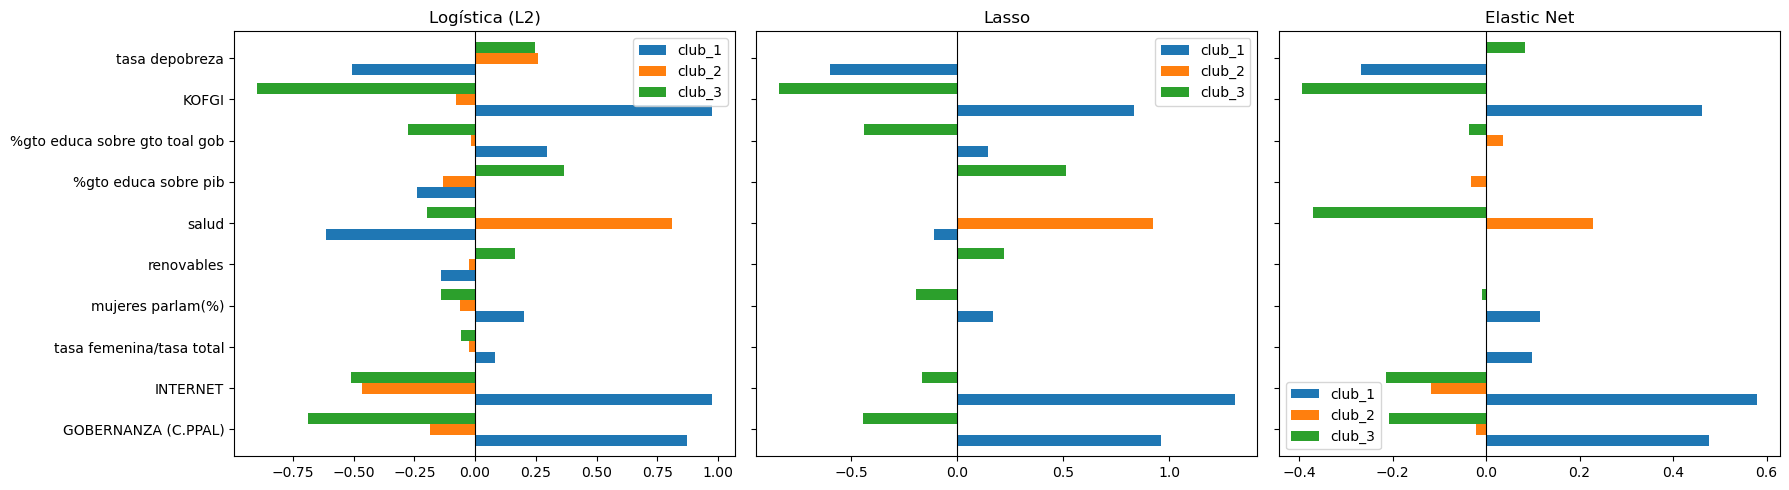

,MDG,MDA
KOFGI,0.2049,0.1080
INTERNET,0.1997,0.0574
GOBERNANZA (C.PPAL),0.1403,0.0316
salud,0.0988,0.0263
tasa femenina/tasa total,0.0592,0.0105
%gto educa sobre pib,0.0572,0.0091
mujeres parlam(%),0.0511,-0.0008
%gto educa sobre gto toal gob,0.0573,-0.0058
renovables,0.0577,-0.0080
tasa depobreza,0.0737,-0.0167


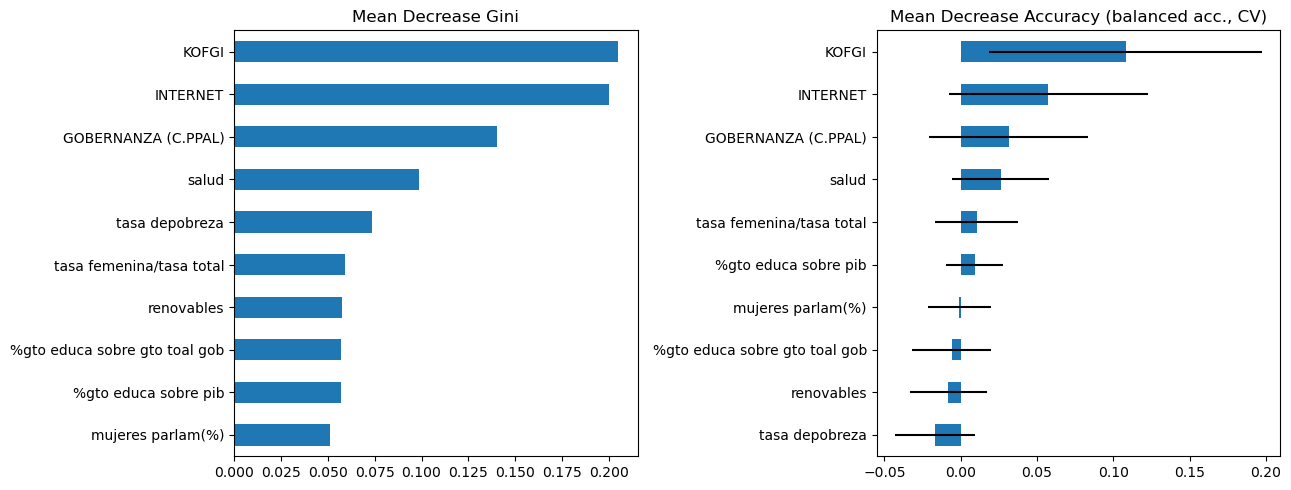

In [17]:
# ---------- 1. Coeficientes (variables estandarizadas -> comparables entre sí) ----------
def tabla_coef(modelo):
    clf = modelo.named_steps["clf"]
    return pd.DataFrame(
        clf.coef_.T, index=X.columns,
        columns=[f"club_{c}" for c in clf.classes_],
    )

modelos_lineales = {
    "Logística (L2)": modelo_log.fit(X, y),
    "Lasso": busqueda_lasso.best_estimator_,
    "Elastic Net": busqueda_en.best_estimator_,
}
coeficientes = {nombre: tabla_coef(m) for nombre, m in modelos_lineales.items()}

for nombre, tabla in coeficientes.items():
    print(f"\n=== Coeficientes {nombre} ===")
    display(tabla.round(3))

fig, ejes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (nombre, tabla) in zip(ejes, coeficientes.items()):
    tabla.plot.barh(ax=ax, width=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

# ---------- 2. Random Forest: MDG y MDA ----------
# MDG (Mean Decrease Gini) = reducción media de impureza (feature_importances_)
rf = crear_rf(n_jobs=N_JOBS).fit(X, y)
mdg = pd.Series(rf.named_steps["clf"].feature_importances_, index=X.columns, name="MDG")

# MDA (Mean Decrease Accuracy) = caída de la balanced accuracy al permutar la variable.
# Se calcula en los datos de test de cada fold (en entrenamiento saldría inflada).
mda_folds = []
for entreno, test in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(X, y):
    m = crear_rf(n_jobs=N_JOBS).fit(X.iloc[entreno], y.iloc[entreno])
    r = permutation_importance(
        m, X.iloc[test], y.iloc[test], scoring="balanced_accuracy",
        n_repeats=50, random_state=SEMILLA,
    )
    mda_folds.append(r.importances_mean)
mda = pd.Series(np.mean(mda_folds, axis=0), index=X.columns, name="MDA")
mda_sd = pd.Series(np.std(mda_folds, axis=0), index=X.columns)

importancias_rf = pd.concat([mdg, mda], axis=1).sort_values("MDA", ascending=False)
display(importancias_rf.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
mdg.sort_values().plot.barh(ax=ejes[0], title="Mean Decrease Gini")
mda.sort_values().plot.barh(ax=ejes[1], xerr=mda_sd[mda.sort_values().index],
                            title="Mean Decrease Accuracy (balanced acc., CV)")
plt.tight_layout()
plt.show()